In [2]:
import sys
from pathlib import Path

# Add project root to sys.path so we can import from utils
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

from utils.plotting import PALETTE, plot_pmf, set_style

# Apply standard style across all plots
set_style()

# Negative Binomial Distribution: Waiting for Multiple Successes & Overdispersed Counts

## 1. Intuition & Motivation

The **Negative Binomial distribution** is one of the most versatile discrete distributions in data science because it solves two distinct, important problems:

### Perspective 1: Waiting for $r$ Successes (Generalizing Geometric)
In the Geometric distribution, we asked: *"How many cold calls until our **1st** sale?"* ($r = 1$).
Now we ask: *"How many cold calls must a salesperson make until they close their **quota of $r = 3$ sales**?"*
The Negative Binomial models the number of failures (or total trials) needed to achieve exactly $r$ successes in repeated, independent Bernoulli trials.

### Perspective 2: Overdispersed Poisson Data (The Workhorse of Count Models)
In real-world data science (e.g., e-commerce orders, insurance claims, bug reports), observed count data frequently violates Poisson's strict rule of $\text{Var} = \mu$. When data exhibits **overdispersion** ($\text{Var} > \mu$), the Negative Binomial distribution is the standard, battle-tested model used in generalized linear models (GLMs).

### SciPy Parameterization Convention
In `scipy.stats.nbinom(n, p)`:
- $n = r$ is the target number of successes.
- $p$ is the probability of success per trial.
- The random variable $k$ is the **number of failures** before the $r$-th success: $k \in \{0, 1, 2, \dots\}$.

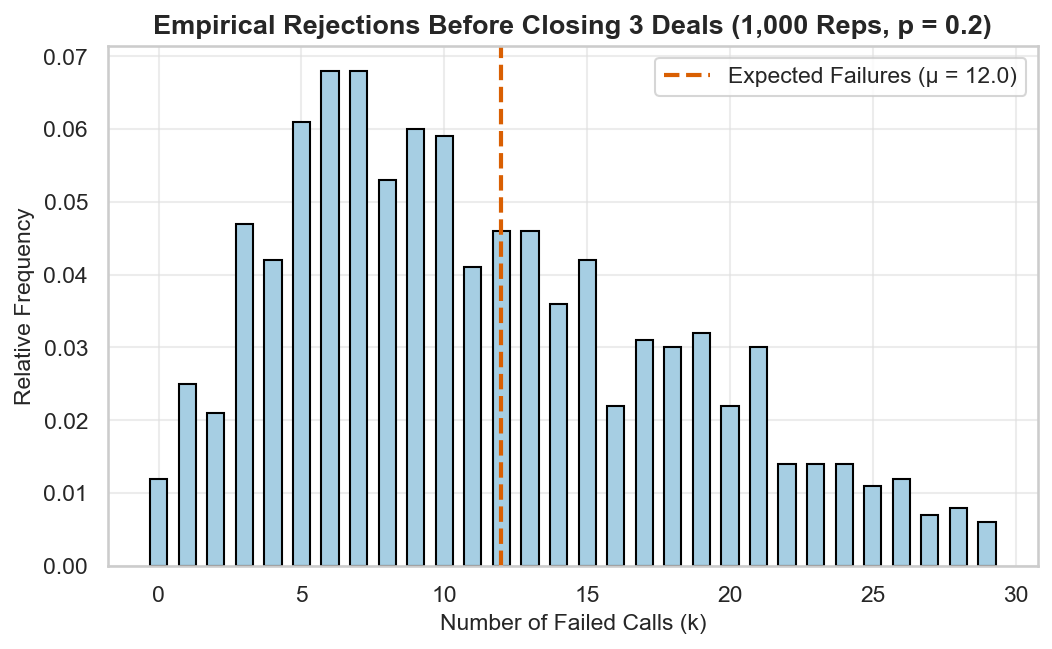

Sample Mean Failures: 11.78 (Theoretical: 12.00)
Sample Variance:      55.67


In [3]:
# Target successes (sales) and conversion probability
r_sales = 3
p_convert = 0.20
n_reps = 1000

# Seed for reproducibility
rng = np.random.default_rng(seed=42)

# Generate failures before 3rd success using SciPy convention
failures = rng.negative_binomial(n=r_sales, p=p_convert, size=n_reps)

# Plot empirical distribution
k_max_obs = int(np.percentile(failures, 98))
counts, bins = np.histogram(failures, bins=np.arange(-0.5, k_max_obs + 1.5, 1))

plt.figure(figsize=(8, 4.5))
plt.bar(
    np.arange(0, k_max_obs + 1),
    counts[: k_max_obs + 1] / n_reps,
    color=PALETTE["fill"],
    edgecolor="black",
    width=0.6,
)

# Theoretical mean failures: r * (1 - p) / p = 3 * 0.8 / 0.2 = 12 failures
mu_theoretical = r_sales * (1 - p_convert) / p_convert
plt.axvline(
    mu_theoretical,
    color=PALETTE["secondary"],
    linestyle="--",
    linewidth=2,
    label=f"Expected Failures (μ = {mu_theoretical:.1f})",
)

plt.title(
    f"Empirical Rejections Before Closing {r_sales} Deals (1,000 Reps, p = {p_convert})",
    weight="bold",
)
plt.xlabel("Number of Failed Calls (k)")
plt.ylabel("Relative Frequency")
plt.legend(frameon=True)
plt.show()

print(f"Sample Mean Failures: {np.mean(failures):.2f} (Theoretical: {mu_theoretical:.2f})")
print(f"Sample Variance:      {np.var(failures, ddof=1):.2f}")

## 2. Mathematical Definition

A discrete random variable $X$ follows a Negative Binomial distribution with parameters $r$ and $p$:
$$X \sim \text{NegativeBinomial}(r, p)$$

### Parameters & Support (Failures Convention)
- **$r \in \{1, 2, 3, \dots\}$**: Target number of successes (stops after the $r$-th success).
- **$p \in (0, 1]$**: Probability of success on each independent trial ($q = 1 - p$ is failure probability).
- **Support**: Number of failures observed: $k \in \{0, 1, 2, 3, \dots\}$.

### Probability Mass Function (PMF) Derivation
If the experiment stops on the $r$-th success after observing $k$ failures:
1. Total trials conducted is $k + r$.
2. The **very last trial must be a success** (the $r$-th success).
3. In the preceding $k + r - 1$ trials, there must have been exactly $r - 1$ successes and $k$ failures, occurring in any order:

$$P(X = k) = \binom{k + r - 1}{k} p^r (1 - p)^k = \binom{k + r - 1}{r - 1} p^r (1 - p)^k$$

*(Why "Negative" Binomial? The binomial coefficient can be algebraically rewritten using negative exponents: $\binom{-r}{k} = (-1)^k \binom{k + r - 1}{k}$.)*

### Cumulative Distribution Function (CDF)
$$F(k) = P(X \le k) = \sum_{i=0}^{\lfloor k \rfloor} \binom{i + r - 1}{i} p^r (1 - p)^i = I_p(r, k + 1)$$
where $I_p(a, b)$ is the regularized incomplete Beta function.

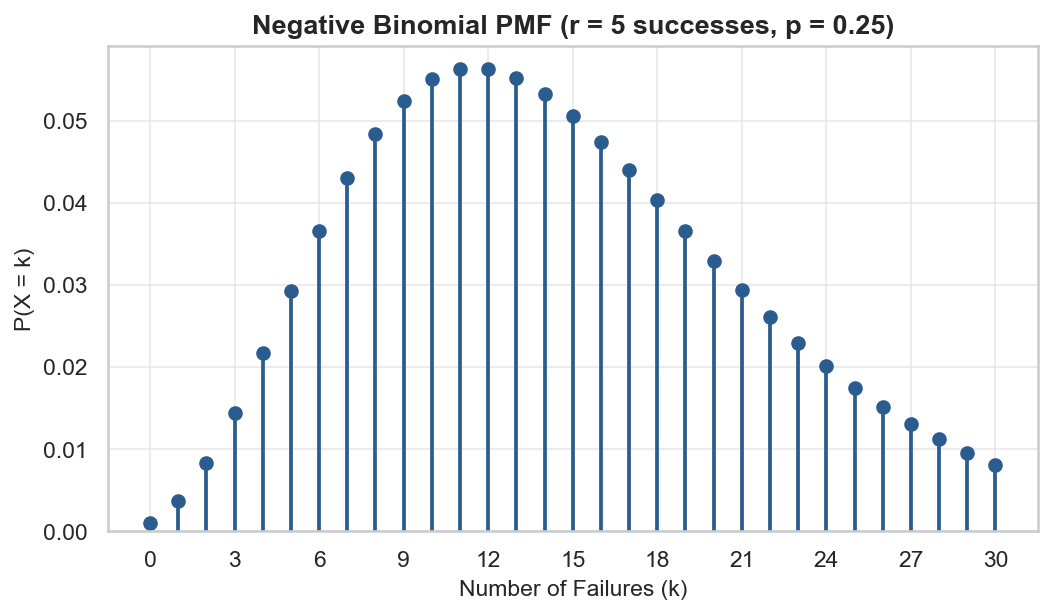

In [8]:
# Parameters
r = 5
p = 0.25
k_support = np.arange(0, 31)  # Range of failures to visualize

# Evaluate exact theoretical PMF: P(X = k failures)
pmf_values = stats.nbinom.pmf(k_support, r, p)

# Plot PMF using our shared helper
fig, ax = plt.subplots(figsize=(8, 4.2))
plot_pmf(
    k_support,
    pmf_values,
    title=f"Negative Binomial PMF (r = {r} successes, p = {p})",
    xlabel="Number of Failures (k)",
    ylabel="P(X = k)",
    ax=ax,
)
ax.set_xticks(range(0, 31, 3))
plt.show()

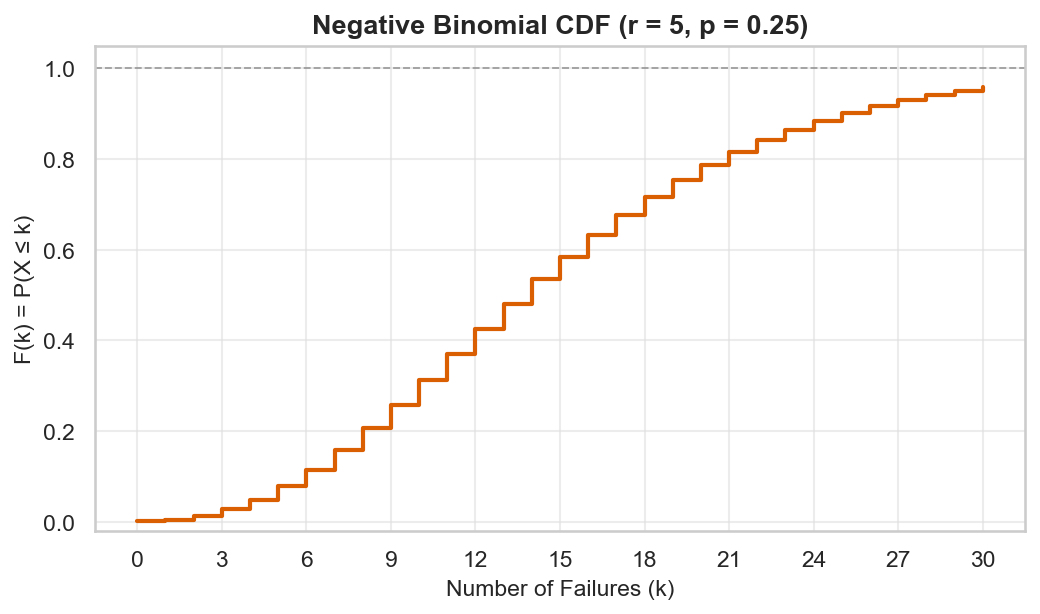

In [9]:
from utils.plotting import plot_cdf

# Evaluate exact theoretical CDF: P(X <= k failures)
cdf_values = stats.nbinom.cdf(k_support, r, p)

fig, ax = plt.subplots(figsize=(8, 4.2))
plot_cdf(
    k_support,
    cdf_values,
    is_discrete=True,
    title=f"Negative Binomial CDF (r = {r}, p = {p})",
    xlabel="Number of Failures (k)",
    ylabel="F(k) = P(X ≤ k)",
    ax=ax,
)
ax.set_xticks(range(0, 31, 3))
plt.show()

## 3. Key Theoretical Properties

For $X \sim \text{NegativeBinomial}(r, p)$ (number of failures before $r$-th success):

### 1. Expected Value (Mean): $\mathbb{E}[X] = \mu$
$$\mu = \frac{r (1 - p)}{p}$$
Each success requires an average of $(1 - p)/p$ failures. For $r$ successes, linearity of expectation gives $r \times \frac{1 - p}{p}$.

### 2. Variance & Standard Deviation: $\text{Var}(X) = \sigma^2$
$$\sigma^2 = \frac{r (1 - p)}{p^2} = \frac{\mu}{p}, \quad \sigma = \frac{\sqrt{r (1 - p)}}{p}$$

> **Key Concept — Overdispersion:**
> Notice that because $p \in (0, 1)$, $\frac{1}{p} > 1$. Therefore:
> $$\text{Var}(X) = \frac{\mu}{p} > \mu$$
> The variance is **strictly greater than the mean**!
> In Generalized Linear Models (GL

In [11]:
# Parameters
r_test = 4
p_test = 0.25

# Analytical moment formulas
mu_formula = r_test * (1 - p_test) / p_test
var_formula = r_test * (1 - p_test) / (p_test**2)
std_formula = np.sqrt(var_formula)
skew_formula = (2 - p_test) / np.sqrt(r_test * (1 - p_test))
kurt_formula = (6 / r_test) + (p_test**2) / (r_test * (1 - p_test))

# SciPy calculation
mu_sp, var_sp, skew_sp, kurt_sp = stats.nbinom.stats(r_test, p_test, moments="mvsk")

print("--- NEGATIVE BINOMIAL THEORETICAL MOMENTS ---")
print(f"Moment               | Analytical |    SciPy")
print("-" * 46)
print(f"Mean (μ)             | {mu_formula:10.4f} | {float(mu_sp):10.4f}")
print(f"Variance (σ²)        | {var_formula:10.4f} | {float(var_sp):10.4f}")
print(f"Std Deviation (σ)    | {std_formula:10.4f} | {np.sqrt(float(var_sp)):10.4f}")
print(f"Skewness (γ₁)        | {skew_formula:10.4f} | {float(skew_sp):10.4f}")
print(f"Excess Kurtosis (γ₂) | {kurt_formula:10.4f} | {float(kurt_sp):10.4f}")
print(f"\nVariance / Mean Ratio (Dispersion Index): {var_formula / mu_formula:.2f}")

--- NEGATIVE BINOMIAL THEORETICAL MOMENTS ---
Moment               | Analytical |    SciPy
----------------------------------------------
Mean (μ)             |    12.0000 |    12.0000
Variance (σ²)        |    48.0000 |    48.0000
Std Deviation (σ)    |     6.9282 |     6.9282
Skewness (γ₁)        |     1.0104 |     1.0104
Excess Kurtosis (γ₂) |     1.5208 |     1.5208

Variance / Mean Ratio (Dispersion Index): 4.00


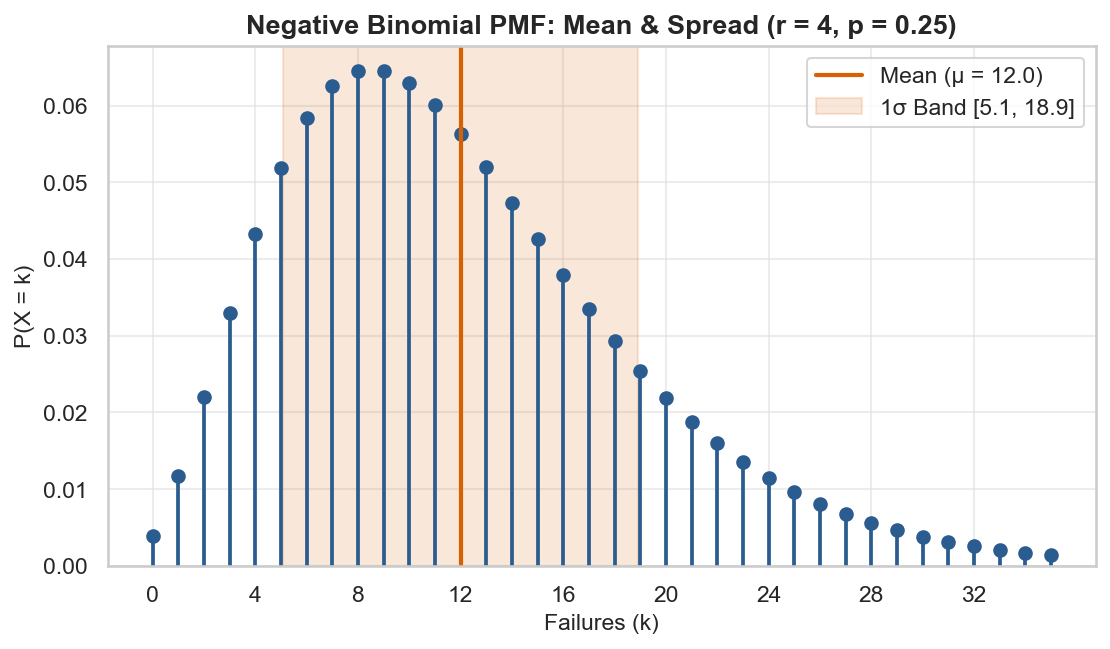

In [12]:
k_grid = np.arange(0, 36)
pmf_grid = stats.nbinom.pmf(k_grid, r_test, p_test)

fig, ax = plt.subplots(figsize=(8.5, 4.5))
plot_pmf(
    k_grid,
    pmf_grid,
    title=f"Negative Binomial PMF: Mean & Spread (r = {r_test}, p = {p_test})",
    xlabel="Failures (k)",
    ylabel="P(X = k)",
    ax=ax,
)

# Mean and 1-Sigma Band
ax.axvline(
    mu_formula,
    color=PALETTE["secondary"],
    linestyle="-",
    linewidth=2,
    label=f"Mean (μ = {mu_formula:.1f})",
)
ax.axvspan(
    max(0, mu_formula - std_formula),
    mu_formula + std_formula,
    color=PALETTE["secondary"],
    alpha=0.15,
    label=f"1σ Band [{max(0, mu_formula - std_formula):.1f}, {mu_formula + std_formula:.1f}]",
)

ax.set_xticks(range(0, 36, 4))
ax.legend(frameon=True)
plt.show()

## 4. Parameter Variation

The Negative Binomial distribution is governed by two parameters: $(r, p)$.

### 1. Effect of changing $r$ (with fixed $p$):
- **$r = 1$**: This is the **Geometric distribution**. The PMF decays monotonically with its peak at $k = 0$ failures.
- **Moderate $r$ (e.g., $r = 3$ to $5$)**: The distribution develops a distinct unimodal hump with positive right-skew.
- **Large $r$ (e.g., $r \ge 10$)**: By the **Central Limit Theorem**, because a Negative Binomial variable is the sum of $r$ independent Geometric variables ($X = \sum_{i=1}^r G_i$), the distribution becomes increasingly symmetric and bell-shaped.

### 2. Effect of changing $p$ (with fixed $r$):
- **Small $p$ (e.g., $p = 0.1$ or $0.2$)**: Success is difficult, resulting in a large mean number of failures ($\mu \uparrow$) and massive variance ($\sigma^2 \uparrow\uparrow$).
- **Large $p$ (e.g., $p = 0.7$)**: Success is easy, so failures are rare and the distribution concentrates tightly near zero.

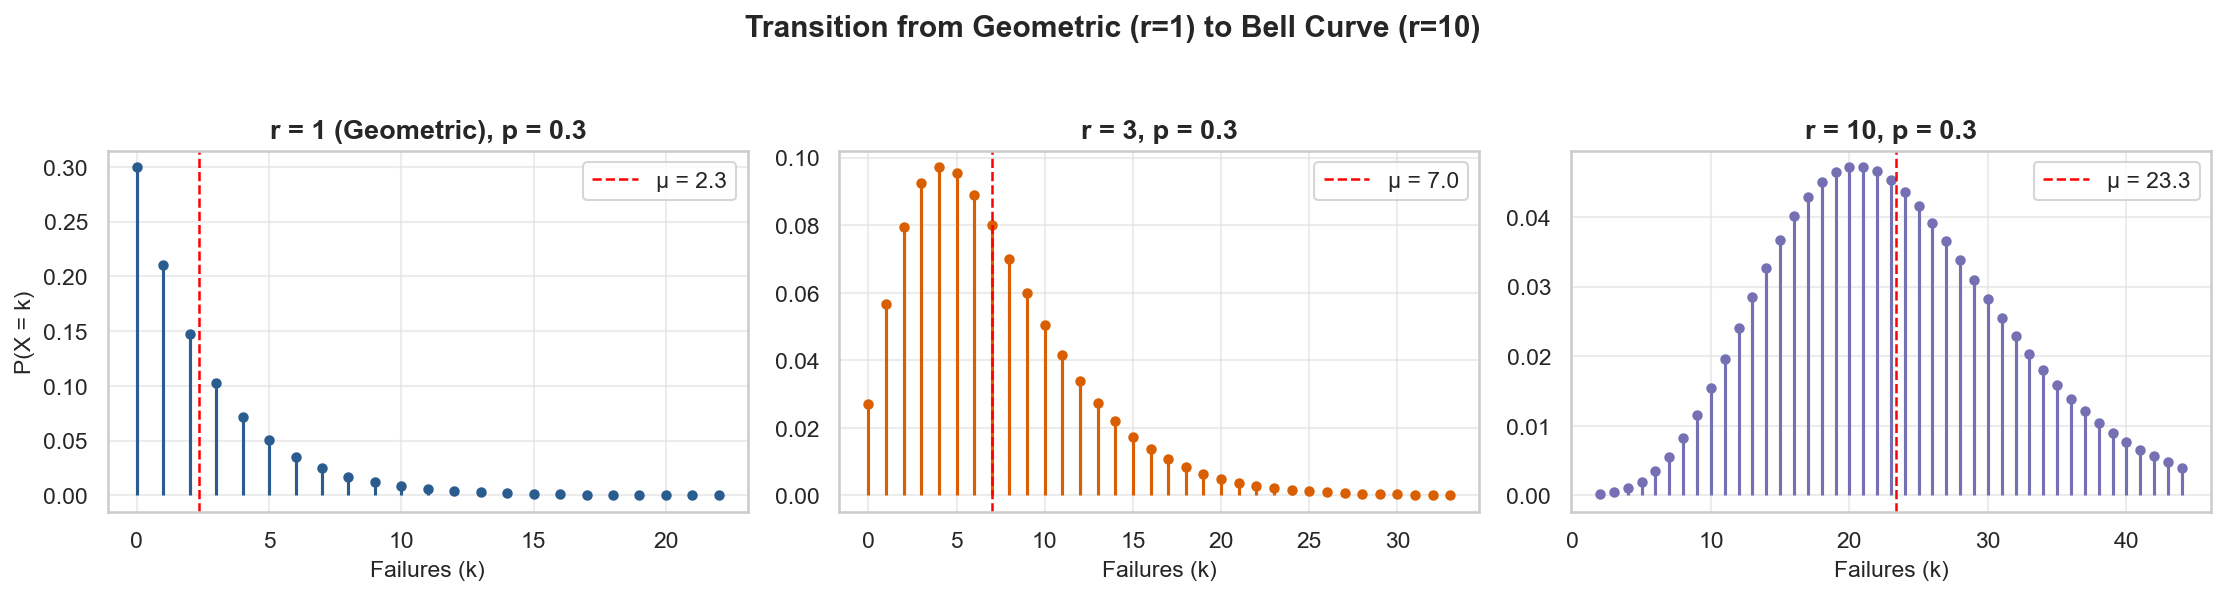

In [13]:
r_list = [1, 3, 10]
p_fixed = 0.3
colors = [PALETTE["primary"], PALETTE["secondary"], PALETTE["accent"]]
k_axis = np.arange(0, 45)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=False)

for ax, r_val, col in zip(axes, r_list, colors):
    pmf = stats.nbinom.pmf(k_axis, r_val, p_fixed)
    mask = pmf > 1e-4

    markerline, stemlines, _ = ax.stem(k_axis[mask], pmf[mask], basefmt=" ")
    plt.setp(markerline, color=col, markersize=4)
    plt.setp(stemlines, color=col, linewidth=1.5)

    mu = r_val * (1 - p_fixed) / p_fixed
    ax.axvline(
        mu, color="red", linestyle="--", linewidth=1.2, label=f"μ = {mu:.1f}"
    )

    title_suffix = " (Geometric)" if r_val == 1 else ""
    ax.set_title(f"r = {r_val}{title_suffix}, p = {p_fixed}", weight="bold")
    ax.set_xlabel("Failures (k)")
    ax.legend(frameon=True, loc="upper right")

axes[0].set_ylabel("P(X = k)")
plt.suptitle(
    "Transition from Geometric (r=1) to Bell Curve (r=10)",
    y=1.04,
    weight="bold",
)
plt.tight_layout()
plt.show()

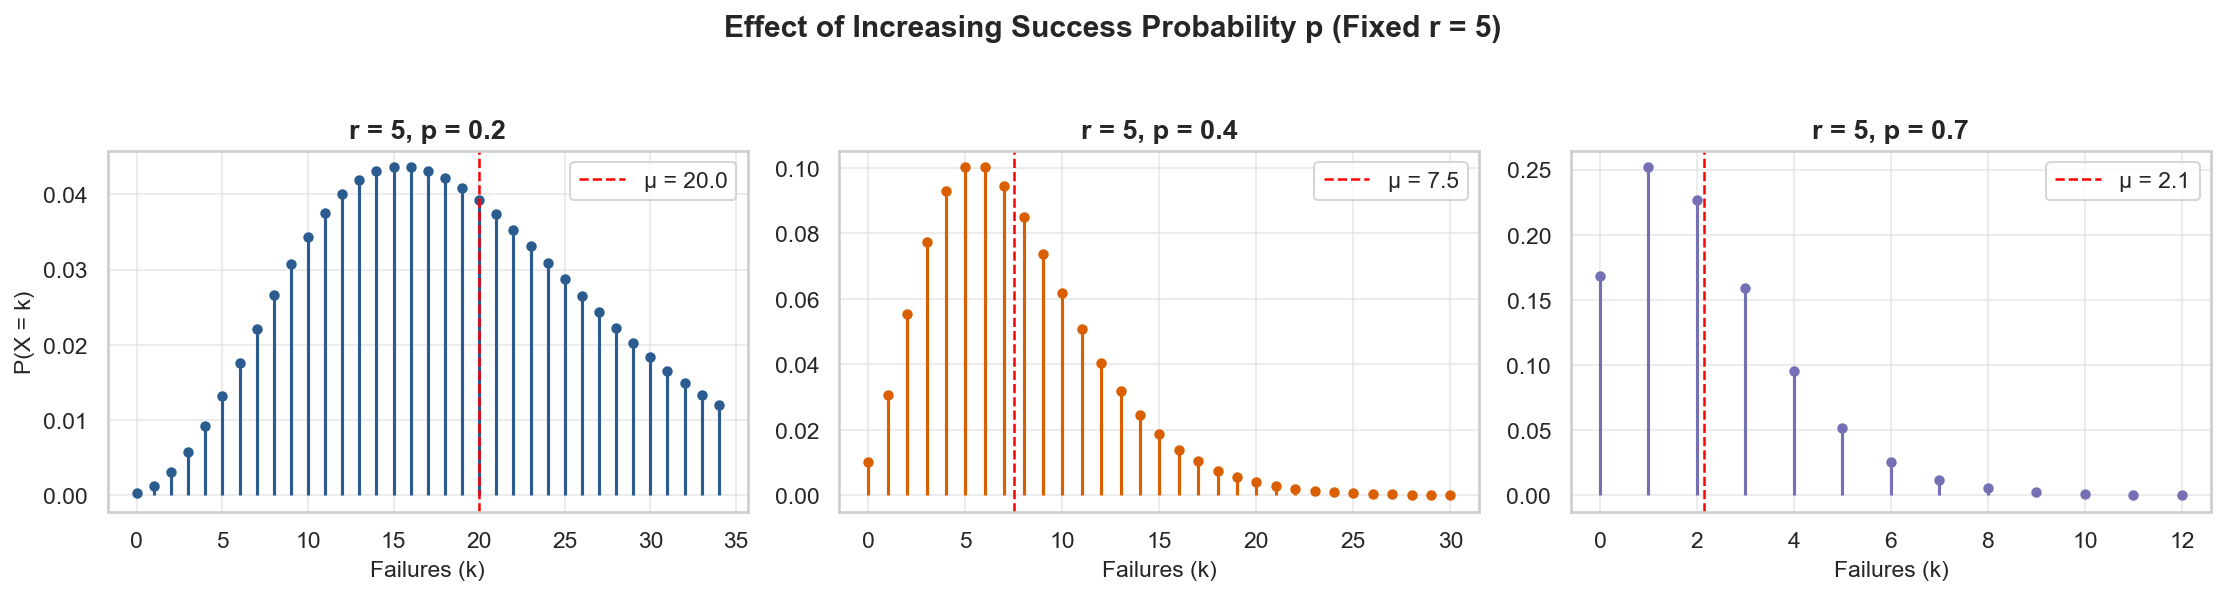

In [14]:
p_list = [0.2, 0.4, 0.7]
r_fixed = 5
k_eval_p = np.arange(0, 35)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=False)

for ax, p_val, col in zip(axes, p_list, colors):
    pmf = stats.nbinom.pmf(k_eval_p, r_fixed, p_val)
    mask = pmf > 1e-4

    markerline, stemlines, _ = ax.stem(k_eval_p[mask], pmf[mask], basefmt=" ")
    plt.setp(markerline, color=col, markersize=4)
    plt.setp(stemlines, color=col, linewidth=1.5)

    mu = r_fixed * (1 - p_val) / p_val
    ax.axvline(
        mu, color="red", linestyle="--", linewidth=1.2, label=f"μ = {mu:.1f}"
    )
    ax.set_title(f"r = {r_fixed}, p = {p_val}", weight="bold")
    ax.set_xlabel("Failures (k)")
    ax.legend(frameon=True, loc="upper right")

axes[0].set_ylabel("P(X = k)")
plt.suptitle(
    "Effect of Increasing Success Probability p (Fixed r = 5)",
    y=1.04,
    weight="bold",
)
plt.tight_layout()
plt.show()

## 5. Simulation & Law of Large Numbers

When we simulate $N$ independent draws $X_1, X_2, \dots, X_N \sim \text{NegativeBinomial}(r, p)$:
- Each observation represents the count of failures observed before the $r$-th success.
- By the **Law of Large Numbers (LLN)**, as $N \to \infty$:
  $$\bar{X}_N = \frac{1}{N} \sum_{i=1}^{N} X_i \xrightarrow{P} \mu = \frac{r(1 - p)}{p}$$
  $$s^2_N = \frac{1}{N - 1} \sum_{i=1}^{N} (X_i - \bar{X}_N)^2 \xrightarrow{P} \sigma^2 = \frac{r(1 - p)}{p^2}$$

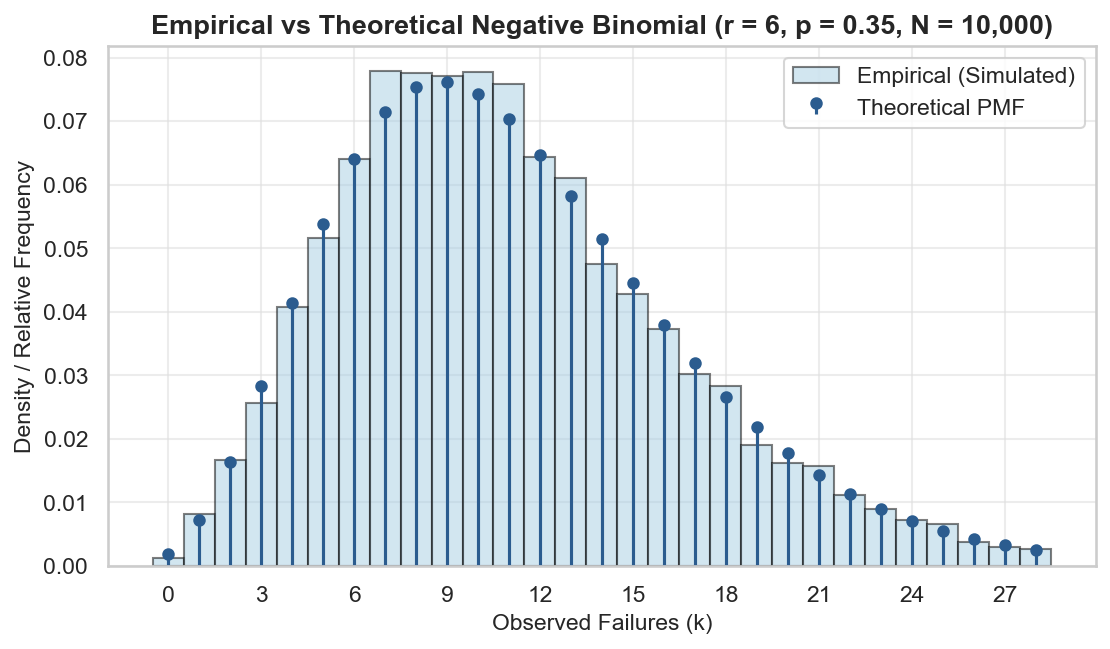

Theoretical Mean: 11.1429  |  Sample Mean: 11.1051
Theoretical Var:  31.8367  |  Sample Var:  31.3962


In [15]:
from utils.plotting import plot_sample_vs_theory

# Parameters
r_sim = 6
p_sim = 0.35
sample_size = 10000

# Theoretical targets
mu_target = r_sim * (1 - p_sim) / p_sim
var_target = r_sim * (1 - p_sim) / (p_sim**2)

# Generate pseudo-random Negative Binomial variates
samples = stats.nbinom.rvs(r_sim, p_sim, size=sample_size, random_state=42)

# Theoretical coordinates
k_max_sim = int(np.percentile(samples, 99))
k_theory = np.arange(0, k_max_sim + 1)
pmf_theory = stats.nbinom.pmf(k_theory, r_sim, p_sim)

# Plot empirical histogram vs theoretical stems
fig, ax = plt.subplots(figsize=(8.5, 4.5))
plot_sample_vs_theory(
    samples=samples[samples <= k_max_sim],
    x_theory=k_theory,
    y_theory=pmf_theory,
    is_discrete=True,
    title=f"Empirical vs Theoretical Negative Binomial (r = {r_sim}, p = {p_sim}, N = {sample_size:,})",
    xlabel="Observed Failures (k)",
    ax=ax,
)
ax.set_xticks(range(0, k_max_sim + 1, 3))
plt.show()

# Empirical checks
print(f"Theoretical Mean: {mu_target:.4f}  |  Sample Mean: {np.mean(samples):.4f}")
print(f"Theoretical Var:  {var_target:.4f}  |  Sample Var:  {np.var(samples, ddof=1):.4f}")

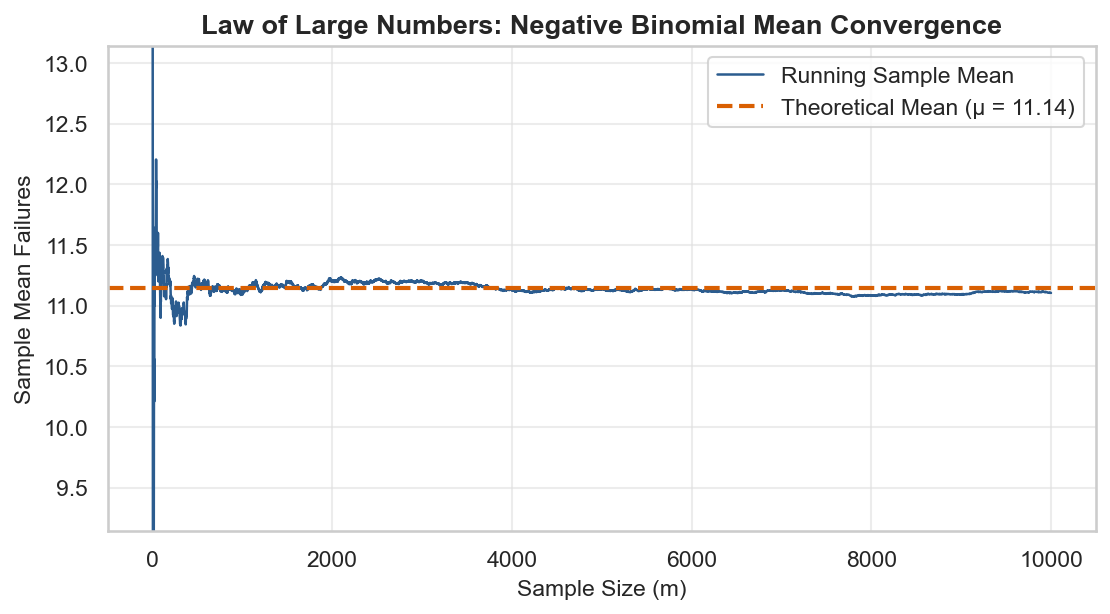

In [16]:
# Compute sequential running mean
m_indices = np.arange(1, sample_size + 1)
running_mean = np.cumsum(samples) / m_indices

plt.figure(figsize=(8.5, 4.2))
plt.plot(
    m_indices,
    running_mean,
    color=PALETTE["primary"],
    linewidth=1.2,
    label="Running Sample Mean",
)
plt.axhline(
    mu_target,
    color=PALETTE["secondary"],
    linestyle="--",
    linewidth=2,
    label=f"Theoretical Mean (μ = {mu_target:.2f})",
)

plt.title("Law of Large Numbers: Negative Binomial Mean Convergence")
plt.xlabel("Sample Size (m)")
plt.ylabel("Sample Mean Failures")
plt.ylim(mu_target - 2.0, mu_target + 2.0)
plt.legend(frameon=True)
plt.show()

## 6. Applied Real-World Use Case: E-Commerce Customer Purchase Frequency

### Scenario
An e-commerce marketplace tracks customer order counts per month.
In customer behavior data, most people make $0$ or $1$ purchase, but a small subset of "VIP power shoppers" make $6$, $10$, or $15$ purchases.
- Mean monthly orders: $\mu = 2.5$ orders/customer
- Variance of monthly orders: $\sigma^2 = 8.75$

### The Overdispersion Problem
Notice the dispersion ratio:
$$\frac{\sigma^2}{\mu} = \frac{8.75}{2.5} = 3.5$$
Because $\sigma^2 > \mu$, a Poisson model cannot describe this customer base.

### Solving for Negative Binomial Parameters:
Using $\mu = \frac{r(1 - p)}{p}$ and $\sigma^2 = \frac{r(1 - p)}{p^2}$:
$$p = \frac{\mu}{\sigma^2} = \frac{2.5}{8.75} \approx 0.2857$$
$$r = \frac{\mu \cdot p}{1 - p} = \frac{2.5 \times 0.2857}{0.7143} = 1.0$$

In [17]:
# Empirical customer parameters
mu_orders = 2.5
var_orders = 8.75

# Derived Negative Binomial parameters
p_nb = mu_orders / var_orders  # 2.5 / 8.75 ≈ 0.2857
r_nb = (mu_orders * p_nb) / (1 - p_nb)  # = 1.0 (Geometric case)

# 1. Non-buyers: P(X = 0 orders)
prob_zero_nb = stats.nbinom.pmf(0, r_nb, p_nb)
prob_zero_poisson = stats.poisson.pmf(0, mu_orders)

# 2. VIP Power Users: P(X >= 6 orders) = P(X > 5)
vip_threshold = 6
prob_vip_nb = stats.nbinom.sf(vip_threshold - 1, r_nb, p_nb)
prob_vip_poisson = stats.poisson.sf(vip_threshold - 1, mu_orders)

print("--- CUSTOMER SEGMENTATION ANALYSIS ---")
print(f"Mean Orders (μ): {mu_orders:.1f}  |  Variance (σ²): {var_orders:.2f} (Overdispersion: {var_orders/mu_orders:.1f}x)\n")
print(f"Segment: Non-Buyers (k = 0 orders)")
print(f"  Negative Binomial: {prob_zero_nb * 100:.2f}%")
print(f"  Poisson (Flawed):  {prob_zero_poisson * 100:.2f}%  <-- Severely underestimates zero-buyers!\n")
print(f"Segment: VIP Power Buyers (k >= {vip_threshold} orders)")
print(f"  Negative Binomial: {prob_vip_nb * 100:.2f}%")
print(f"  Poisson (Flawed):  {prob_vip_poisson * 100:.2f}%  <-- Misses 70% of high-value revenue!")

--- CUSTOMER SEGMENTATION ANALYSIS ---
Mean Orders (μ): 2.5  |  Variance (σ²): 8.75 (Overdispersion: 3.5x)

Segment: Non-Buyers (k = 0 orders)
  Negative Binomial: 28.57%
  Poisson (Flawed):  8.21%  <-- Severely underestimates zero-buyers!

Segment: VIP Power Buyers (k >= 6 orders)
  Negative Binomial: 13.28%
  Poisson (Flawed):  4.20%  <-- Misses 70% of high-value revenue!


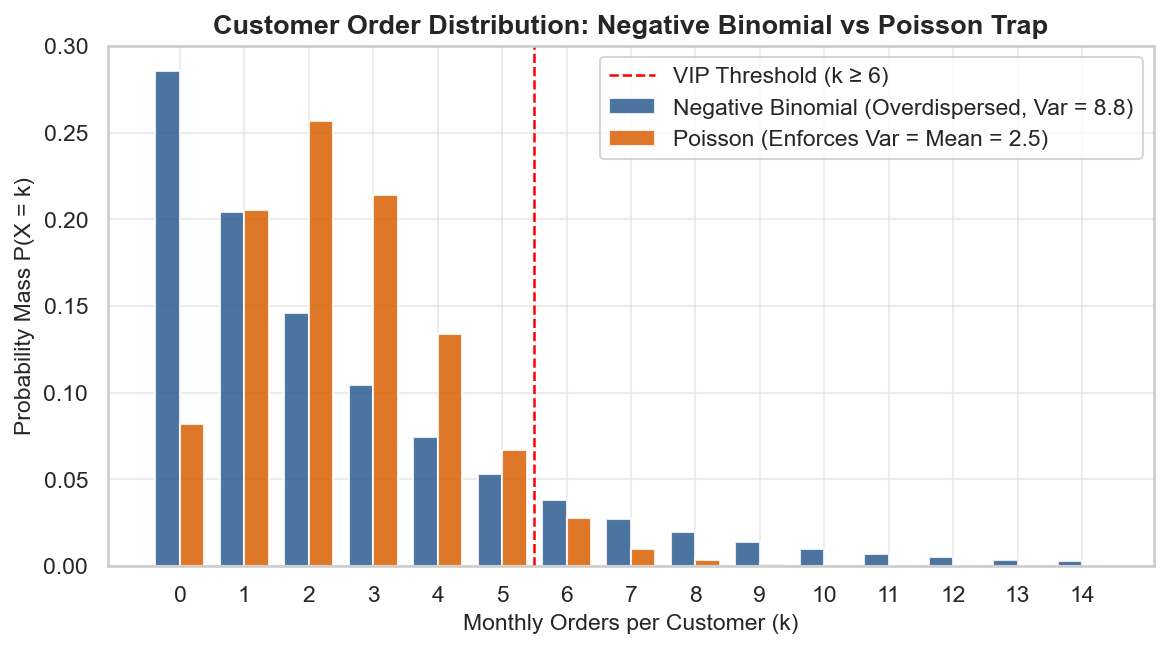

In [18]:
k_eval = np.arange(0, 15)
pmf_nb = stats.nbinom.pmf(k_eval, r_nb, p_nb)
pmf_pois = stats.poisson.pmf(k_eval, mu_orders)

fig, ax = plt.subplots(figsize=(9, 4.5))
bar_width = 0.38

ax.bar(
    k_eval - bar_width / 2,
    pmf_nb,
    width=bar_width,
    label=f"Negative Binomial (Overdispersed, Var = {var_orders:.1f})",
    color=PALETTE["primary"],
    alpha=0.85,
)
ax.bar(
    k_eval + bar_width / 2,
    pmf_pois,
    width=bar_width,
    label=f"Poisson (Enforces Var = Mean = {mu_orders:.1f})",
    color=PALETTE["secondary"],
    alpha=0.85,
)

# Highlight VIP cutoff
ax.axvline(vip_threshold - 0.5, color="red", linestyle="--", linewidth=1.2, label=f"VIP Threshold (k ≥ {vip_threshold})")

ax.set_title("Customer Order Distribution: Negative Binomial vs Poisson Trap", weight="bold")
ax.set_xlabel("Monthly Orders per Customer (k)")
ax.set_ylabel("Probability Mass P(X = k)")
ax.set_xticks(k_eval)
ax.legend(frameon=True)
plt.show()

## 7. Parameter Estimation (Maximum Likelihood Estimation - MLE)

Given a sample of $N$ count observations $k_1, k_2, \dots, k_N$, how do we estimate the parameters $(r, p)$?

### The Log-Likelihood Function
Using the continuous Gamma function $\Gamma(n) = (n - 1)!$ for generalized $r > 0$:
$$\ln L(r, p) = \sum_{i=1}^{N} \Big[ \ln \Gamma(k_i + r) - \ln \Gamma(r) - \ln(k_i!) + r \ln(p) + k_i \ln(1 - p) \Big]$$

### Solving for $p$ (Given $r$):
Setting $\frac{\partial \ln L}{\partial p} = 0$:
$$\frac{N r}{p} - \frac{\sum k_i}{1 - p} = 0 \implies \hat{p}(r) = \frac{r}{r + \bar{k}}$$

### Why Numerical Optimization is Required for $r$:
Differentiating with respect to $r$ yields an equation involving the **digamma function** $\psi(r) = \frac{d}{dr}\ln\Gamma(r)$:
$$\sum_{i=1}^{N} \psi(k_i + r) - N \psi(r) + N \ln(p) = 0$$
This transcendental equation **has no closed-form algebraic solution**. We must find the joint optimum $(r, p)$ using numerical optimization (e.g., Nelder-Mead or L-BFGS-B).

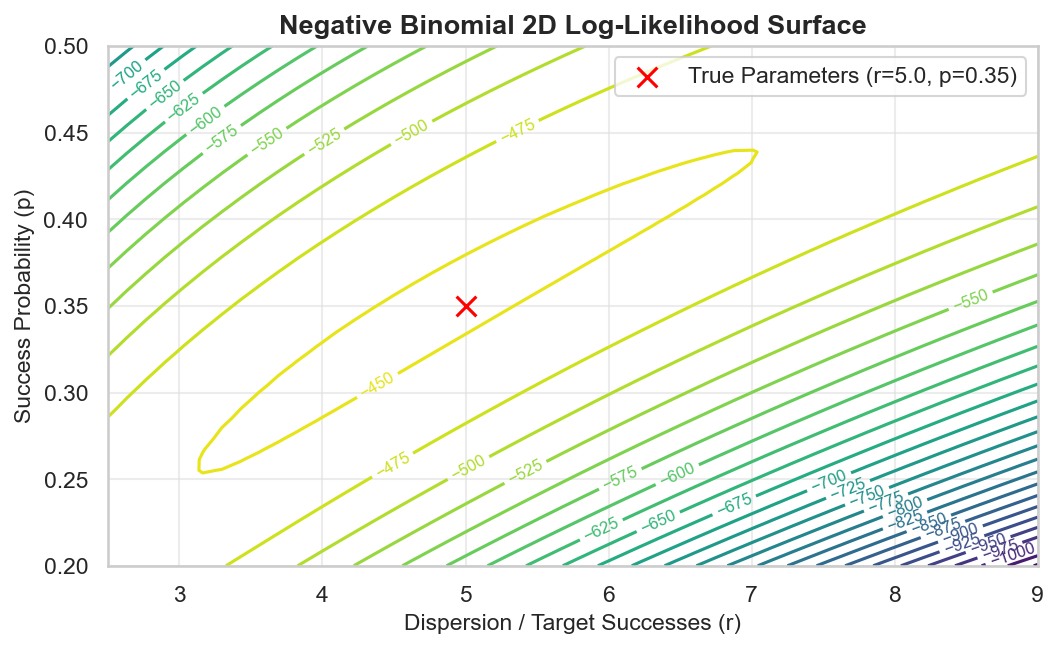

In [20]:
# True parameters
r_true = 5.0
p_true = 0.35
N_obs = 150

# Generate synthetic observations
data_nb = stats.nbinom.rvs(r_true, p_true, size=N_obs, random_state=123)

# 2D Grid search for visualization
r_candidates = np.linspace(2.5, 9.0, 50)
p_candidates = np.linspace(0.20, 0.50, 50)
R_grid, P_grid = np.meshgrid(r_candidates, p_candidates)


def compute_log_lik_point(r_val, p_val, data):
    return np.sum(stats.nbinom.logpmf(data, r_val, p_val))


log_lik_surface = np.zeros_like(R_grid)
for i in range(R_grid.shape[0]):
    for j in range(R_grid.shape[1]):
        log_lik_surface[i, j] = compute_log_lik_point(
            R_grid[i, j], P_grid[i, j], data_nb
        )

# Contour plot of log-likelihood surface
plt.figure(figsize=(8, 4.5))
contours = plt.contour(
    R_grid, P_grid, log_lik_surface, levels=25, cmap="viridis"
)
plt.clabel(contours, inline=True, fontsize=8)
plt.scatter(
    [r_true],
    [p_true],
    color="red",
    s=90,
    zorder=5,
    marker="x",
    label=f"True Parameters (r={r_true}, p={p_true})",
)

plt.title("Negative Binomial 2D Log-Likelihood Surface", weight="bold")
plt.xlabel("Dispersion / Target Successes (r)")
plt.ylabel("Success Probability (p)")
plt.legend(frameon=True)
plt.show()

In [21]:
from scipy.optimize import minimize


# Negative Log-Likelihood objective function
def neg_log_lik_nb(params, data):
    r_val, p_val = params
    # Enforce parameter bounds to prevent invalid probabilities
    if r_val <= 0.01 or p_val <= 0.001 or p_val >= 0.999:
        return 1e9
    return -np.sum(stats.nbinom.logpmf(data, r_val, p_val))


# Initial guess using Method of Moments:
x_bar = np.mean(data_nb)
s_sq = np.var(data_nb, ddof=1)
p_init = np.clip(x_bar / s_sq, 0.05, 0.95)
r_init = np.clip(x_bar * p_init / (1 - p_init), 0.5, 20.0)

# Optimize
res = minimize(
    neg_log_lik_nb,
    x0=[r_init, p_init],
    args=(data_nb,),
    bounds=[(0.1, 50.0), (0.01, 0.99)],
    method="L-BFGS-B",
)

r_mle, p_mle = res.x

print("--- MAXIMUM LIKELIHOOD ESTIMATION RESULTS ---")
print(f"Sample Size (N):            {N_obs}")
print(f"Sample Mean (k̄):            {x_bar:.2f}")
print(f"Sample Variance (s²):       {s_sq:.2f}\n")
print(f"Parameter | True Value | MLE Estimate")
print("-" * 38)
print(f"r         | {r_true:10.4f} | {r_mle:10.4f}")
print(f"p         | {p_true:10.4f} | {p_mle:10.4f}")
print(
    f"\nEstimated Model Mean:  {r_mle * (1 - p_mle) / p_mle:.2f} (matches k̄ = {x_bar:.2f})"
)

--- MAXIMUM LIKELIHOOD ESTIMATION RESULTS ---
Sample Size (N):            150
Sample Mean (k̄):            9.03
Sample Variance (s²):       25.64

Parameter | True Value | MLE Estimate
--------------------------------------
r         |     5.0000 |     4.6181
p         |     0.3500 |     0.3385

Estimated Model Mean:  9.03 (matches k̄ = 9.03)


## 8. Related Distributions & Summary

The Negative Binomial distribution ties together the entire discrete probability landscape:

1. **Geometric Distribution**:
   - The special case where $r = 1$: $\text{NegativeBinomial}(1, p) \equiv \text{Geometric}(p)$ (failures before the 1st success).
   - A Negative Binomial variable is the sum of $r$ independent Geometric variables: $X = \sum_{i=1}^r G_i$.

2. **Poisson Distribution (Limiting Case as $r \to \infty$)**:
   - As $r \to \infty$ and $p \to 1$ such that the mean $\mu = \frac{r(1 - p)}{p} = \lambda$ remains constant:
     $$\lim_{r \to \infty} \text{NegativeBinomial}(r, p) = \text{Poisson}(\lambda)$$
   - The quadratic variance term $\mu + \mu^2/r$ decays to $\mu$, recovering Poisson equidispersion.

3. **Poisson-Gamma Mixture Model**:
   - If individual entities have Poisson arrival rates $\lambda$, but the rates themselves vary across the population according to a continuous **Gamma distribution** ($\lambda \sim \text{Gamma}$), the resulting marginal count distribution across the whole population is **Negative Binomial**.
   - This hierarchical formulation explains why it is the default distribution for modeling web traffic, bug counts, and customer purchases.

4. **Binomial Distribution (Inverted Stopping Condition)**:
   - **Binomial**: Fixes total trials $n$ and counts the random number of successes.
   - **Negative Binomial**: Fixes required successes $r$ and counts the random number of trials/failures needed.

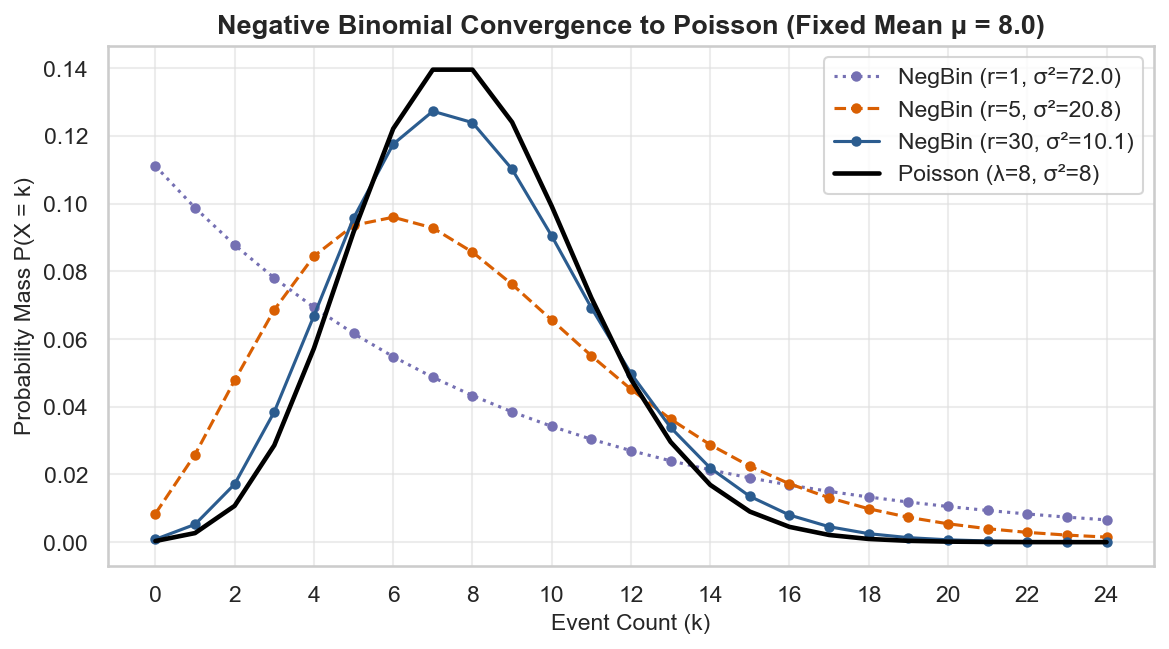

In [22]:
# Fixed mean across all distributions: mu = 8.0
mu_fixed = 8.0
k_axis = np.arange(0, 25)

# Values of r to test (from low to high)
r_values = [1, 5, 30]
# Derive corresponding p for each r: p = r / (r + mu)
p_values = [r_val / (r_val + mu_fixed) for r_val in r_values]

fig, ax = plt.subplots(figsize=(9, 4.5))

# Plot Negative Binomial PMFs as r grows
styles = [":", "--", "-"]
colors = [PALETTE["accent"], PALETTE["secondary"], PALETTE["primary"]]

for r_val, p_val, ls, col in zip(r_values, p_values, styles, colors):
    pmf_nb = stats.nbinom.pmf(k_axis, r_val, p_val)
    var_nb = r_val * (1 - p_val) / (p_val**2)
    ax.plot(
        k_axis,
        pmf_nb,
        linestyle=ls,
        marker="o",
        markersize=4,
        color=col,
        label=f"NegBin (r={r_val}, σ²={var_nb:.1f})",
    )

# Overlay Theoretical Poisson(lambda = 8.0)
pmf_pois = stats.poisson.pmf(k_axis, mu_fixed)
ax.plot(
    k_axis,
    pmf_pois,
    color="black",
    linewidth=2.2,
    label=f"Poisson (λ={mu_fixed:.0f}, σ²={mu_fixed:.0f})",
)

ax.set_title("Negative Binomial Convergence to Poisson (Fixed Mean μ = 8.0)", weight="bold")
ax.set_xlabel("Event Count (k)")
ax.set_ylabel("Probability Mass P(X = k)")
ax.set_xticks(range(0, 25, 2))
ax.legend(frameon=True)
plt.show()

### Summary Card: Negative Binomial Distribution

| Property | Formulation (Failures Convention, $k \ge 0$) |
| :--- | :--- |
| **Notation** | $X \sim \text{NegativeBinomial}(r, p)$ |
| **Parameters** | $r > 0$ (target successes / dispersion parameter), $p \in (0, 1]$ (success probability) |
| **Support** | $k \in \{0, 1, 2, 3, \dots\}$ (number of failures before $r$-th success) |
| **PMF** | $P(X = k) = \binom{k + r - 1}{k} p^r (1 - p)^k$ |
| **CDF** | $F(k) = I_p(r, k + 1)$ (Regularized Incomplete Beta) |
| **Mean ($\mu$)** | $\frac{r(1 - p)}{p}$ |
| **Variance ($\sigma^2$)** | $\frac{r(1 - p)}{p^2} = \mu + \frac{\mu^2}{r}$ (Overdispersion: $\text{Var} > \mu$) |
| **Skewness ($\gamma_1$)** | $\frac{2 - p}{\sqrt{r(1 - p)}}$ |
| **Excess Kurtosis ($\gamma_2$)** | $\frac{6}{r} + \frac{p^2}{r(1 - p)}$ |
| **MLE Estimator** | Numerical optimization required for joint $(r, p)$; $\hat{p} = \frac{r}{r + \bar{k}}$ |
| **Hierarchical Identity** | Continuous Poisson-Gamma Mixture |
| **Key Use Cases** | Customer purchase frequency, overdispersed count regression (GLMs), insurance claims, genomic sequencing reads |